# ChurnLens retention story

**Question for the business:** We grew ARR to about $42M, but are we keeping the customers we win?
And can we see churn coming early enough to do something about it?

This notebook answers three questions using the warehouse built in Phase 2:

1. **Which segment loses the most revenue to churn?**
2. **Does low seat utilization in a customer's first 90 days predict churn at their first renewal?**
3. **Do support problems and falling usage show up before a customer churns?**

The answers shape Phase 4: they tell us which signals belong in the health score and churn model.

> All data is synthetic (see `generate/`). The numbers quoted in the text come from the default run
> (`seed 42`, 3,000 accounts). If you change `config.py`, the charts will update but the text won't.

**How to run:** in the project folder, run `uv run run.py build` first. Then open this file in VS Code,
choose the `.venv` Python kernel when asked (top right), and click **Run All**.

In [1]:
# --- Setup -------------------------------------------------------------------
# We query DuckDB with SQL and get pandas DataFrames back, then chart them with matplotlib.
import math
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Let the notebook import config.py from the project folder (one level up).
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()))
import config

# read_only=True: the notebook can never change the warehouse by accident.
con = duckdb.connect(str(config.WAREHOUSE_PATH), read_only=True)


def q(sql: str):
    """Run a SQL query against the warehouse and return a pandas DataFrame."""
    return con.sql(sql).df()


# One color per segment, used in every chart so readers learn them once.
SEGMENT_COLORS = {"SMB": "#d1495b", "Mid-Market": "#edae49", "Enterprise": "#00798c", "All": "#30343f"}
SEGMENTS = ["SMB", "Mid-Market", "Enterprise"]
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
millions = mtick.FuncFormatter(lambda x, _: f"${x / 1e6:.0f}M")

## 1. The headline: growing, but leaking

First, the big picture. ARR at each month end, and the 12-month net and gross revenue retention.

- **NRR (net revenue retention):** of the ARR we had 12 months ago, how much do those same customers pay now, including expansion?
- **GRR (gross revenue retention):** the same, but expansion doesn't count, so it can never exceed 100%.

Exact definitions are in `docs/metrics.md`.

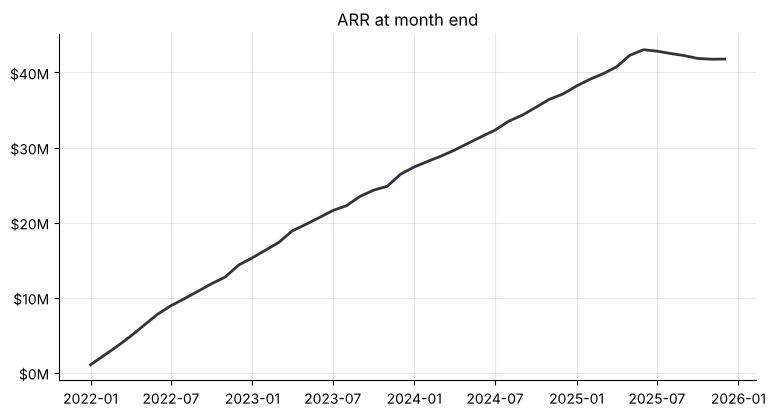

,segment,starting_customers,retained_customers,starting_arr,ending_arr,nrr,grr
0,All,2033,1591,37127442.0,34519143.0,0.9297,0.8391
1,SMB,1080,793,3115161.0,2552811.0,0.8195,0.7179
2,Mid-Market,615,506,9099649.0,8339644.0,0.9165,0.8179
3,Enterprise,338,292,24912632.0,23626688.0,0.9484,0.8620


In [2]:
bridge = q("SELECT month_start, ending_arr, customers FROM mart_arr_bridge ORDER BY month_start")

fig, ax = plt.subplots()
ax.plot(bridge["month_start"], bridge["ending_arr"], color=SEGMENT_COLORS["All"], linewidth=2)
ax.yaxis.set_major_formatter(millions)
ax.set_title("ARR at month end")
plt.show()

latest = q("""
    SELECT segment, starting_customers, retained_customers,
           round(starting_arr) AS starting_arr, round(ending_arr) AS ending_arr, nrr, grr
    FROM metric_retention_12m
    WHERE month_start = (SELECT max(month_start) FROM metric_retention_12m)
    ORDER BY CASE segment WHEN 'All' THEN 0 WHEN 'SMB' THEN 1 WHEN 'Mid-Market' THEN 2 ELSE 3 END
""")
latest

**Reading it:** ARR grew from under $15M at the end of 2022 to about $42M, but almost all of that growth came from new logos.
NRR for the 12 months to December 2025 is **93%**, and GRR is **84%**. Healthy B2B SaaS companies
usually aim for NRR above 100% and GRR around 90%. That means the existing customer base is shrinking,
and new sales are covering the hole.

Revenue retention also isn't the same across segments. Let's see how it moves over time.

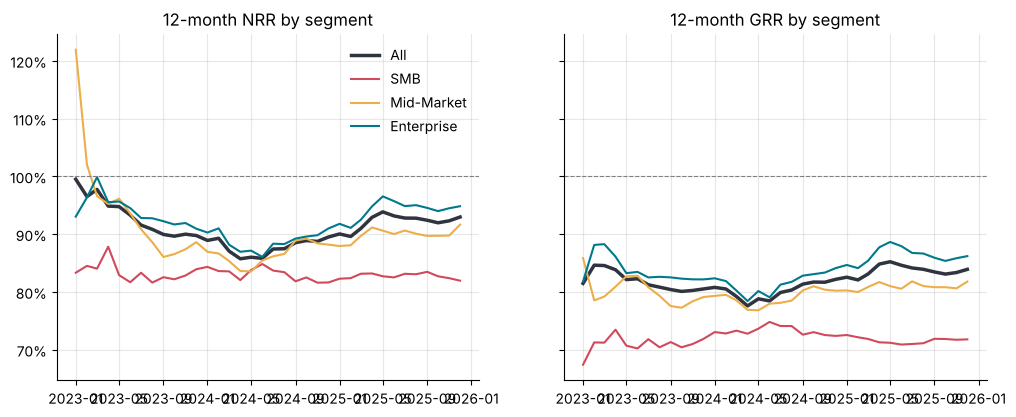

In [3]:
ret = q("SELECT month_start, segment, nrr, grr FROM metric_retention_12m ORDER BY month_start")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, metric in zip(axes, ["nrr", "grr"]):
    for seg in ["All", *SEGMENTS]:
        d = ret[ret["segment"] == seg]
        ax.plot(d["month_start"], d[metric], label=seg, color=SEGMENT_COLORS[seg],
                linewidth=2.5 if seg == "All" else 1.5)
    ax.axhline(1.0, color="grey", linewidth=0.8, linestyle="--")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_title(f"12-month {metric.upper()} by segment")
axes[0].legend(frameon=False)
plt.show()

## 2. Question 1: which segment loses the most revenue?

There are two ways to measure churn, and they give opposite answers.

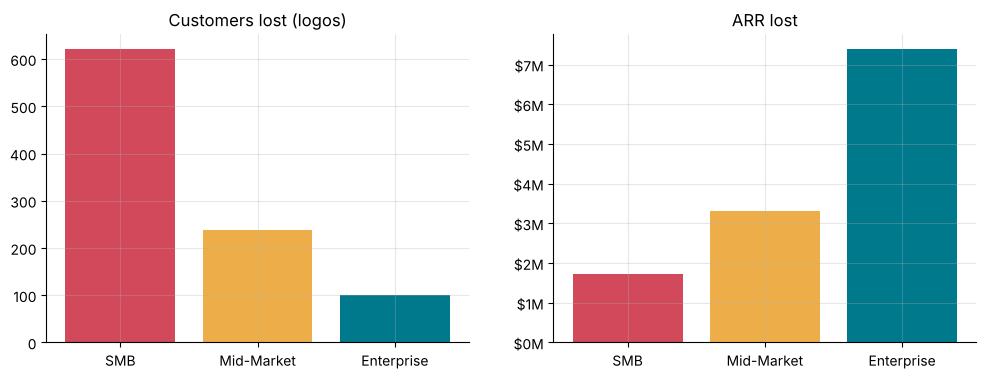

,churned_customers,churned_arr
segment,,
SMB,621,1714541.0
Mid-Market,239,3318118.0
Enterprise,101,7388648.0


In [4]:
churn_by_segment = q("""
    SELECT a.segment,
           count(*)                 AS churned_customers,
           round(-sum(f.arr_change)) AS churned_arr
    FROM fact_arr_monthly f
    JOIN dim_account a USING (account_id)
    WHERE f.arr_change_type = 'churn'
    GROUP BY a.segment
""").set_index("segment").loc[SEGMENTS]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = [SEGMENT_COLORS[s] for s in SEGMENTS]
axes[0].bar(SEGMENTS, churn_by_segment["churned_customers"], color=colors)
axes[0].set_title("Customers lost (logos)")
axes[1].bar(SEGMENTS, churn_by_segment["churned_arr"], color=colors)
axes[1].yaxis.set_major_formatter(millions)
axes[1].set_title("ARR lost")
plt.show()
churn_by_segment

**Answer:** it depends on how you count, and both answers matter.

- **SMB loses the most customers** (621 logos) and has the worst retention *rate* (GRR around 72%).
- **Enterprise loses the most money.** Only 101 logos churned, but they took about **$7.4M of ARR**,
  four times what SMB lost (about $1.7M).

**So what:** one playbook can't fix both. Enterprise churn needs high-touch attention, with CSMs
reviewing risk on every large account well before renewal. SMB churn is a volume problem, better
handled with scaled "tech-touch" programs such as onboarding emails and in-app guidance.
A churn model that ranks accounts by *ARR at risk*, not just churn probability, serves both.

### Cohort retention

Customers grouped by the quarter they signed. Each cell shows the share of the cohort's starting ARR
still with us N months later. Read across a row to follow one cohort over time.

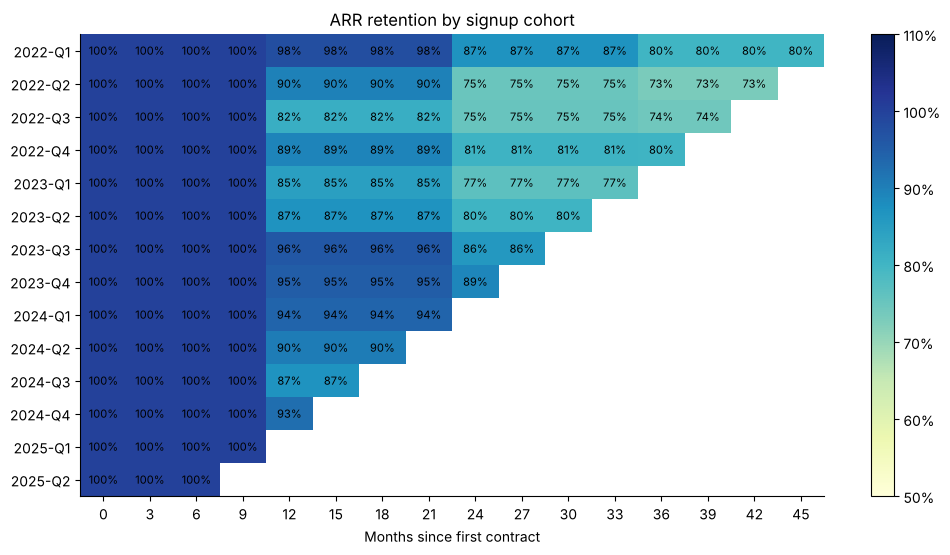

In [5]:
cohorts = q("""
    SELECT cohort_quarter, months_since_start,
           sum(retained_arr) / sum(cohort_starting_arr) AS arr_retention
    FROM mart_cohort_retention
    GROUP BY 1, 2
""")
grid = cohorts.pivot(index="cohort_quarter", columns="months_since_start", values="arr_retention")
grid = grid[[c for c in grid.columns if c % 3 == 0]]  # every 3rd month keeps it readable

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(grid.values, cmap="YlGnBu", vmin=0.5, vmax=1.1, aspect="auto")
ax.set_xticks(range(len(grid.columns)), [str(c) for c in grid.columns])
ax.set_yticks(range(len(grid.index)), grid.index)
ax.set_xlabel("Months since first contract")
ax.set_title("ARR retention by signup cohort")
ax.grid(False)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        if not math.isnan(v):  # skip empty cells: months this cohort hasn't reached yet
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, format=mtick.PercentFormatter(1.0))
plt.show()

**Reading it:** the cells change mostly at months 12, 24, and 36, because contracts are annual and
customers can only leave at renewal. Cohorts keep 82–98% of their ARR through the first renewal,
then drop again at the second. **The first renewal is the moment that matters most.**

## 3. Question 2: do slow starts predict churn?

For each customer, take the average seat utilization over their first 3 months, then check whether
they churned at their first renewal. Utilization means monthly active users ÷ licensed seats.

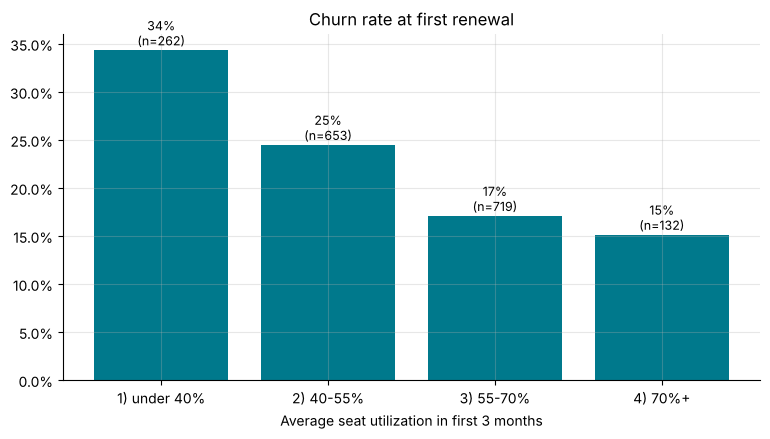

,early_utilization_band,customers,first_renewal_churn_rate
0,1) under 40%,262,0.343511
1,2) 40-55%,653,0.245023
2,3) 55-70%,719,0.171071
3,4) 70%+,132,0.151515


In [6]:
early = q("""
    WITH first_90_days AS (
        SELECT account_id, avg(seat_utilization) AS early_utilization
        FROM mart_account_month
        WHERE tenure_months BETWEEN 0 AND 2
        GROUP BY account_id
        HAVING count(*) = 3                -- only customers whose first 3 months we fully observed
    ),
    first_renewal AS (
        SELECT account_id, renewal_outcome = 'churned' AS churned
        FROM fact_contract
        WHERE contract_number = 1 AND renewal_outcome <> 'open'
    )
    SELECT CASE WHEN early_utilization < 0.40 THEN '1) under 40%'
                WHEN early_utilization < 0.55 THEN '2) 40-55%'
                WHEN early_utilization < 0.70 THEN '3) 55-70%'
                ELSE '4) 70%+' END          AS early_utilization_band,
           count(*)                        AS customers,
           avg(churned::INT)               AS first_renewal_churn_rate
    FROM first_90_days JOIN first_renewal USING (account_id)
    GROUP BY 1 ORDER BY 1
""")

fig, ax = plt.subplots()
ax.bar(early["early_utilization_band"], early["first_renewal_churn_rate"], color="#00798c")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Average seat utilization in first 3 months")
ax.set_title("Churn rate at first renewal")
for i, (rate, n) in enumerate(zip(early["first_renewal_churn_rate"], early["customers"])):
    ax.text(i, rate + 0.005, f"{rate:.0%}\n(n={n})", ha="center", fontsize=9)
plt.show()
early

**Answer: yes.** Customers using fewer than 40% of their seats in the first 90 days churn at their
first renewal **34%** of the time. For customers above 70% the rate is **15%**, so a slow start more
than doubles the risk. The signal shows up **9 months before the renewal date**, which is plenty
of time to act.

**So what:** a 90-day onboarding check (are they above 55% utilization?) is a cheap early warning.
Early utilization goes into the churn model as a feature.

## 4. Question 3: what do the months before a churn look like?

Compare contracts that churned with contracts that renewed, month by month as the renewal date
approaches.

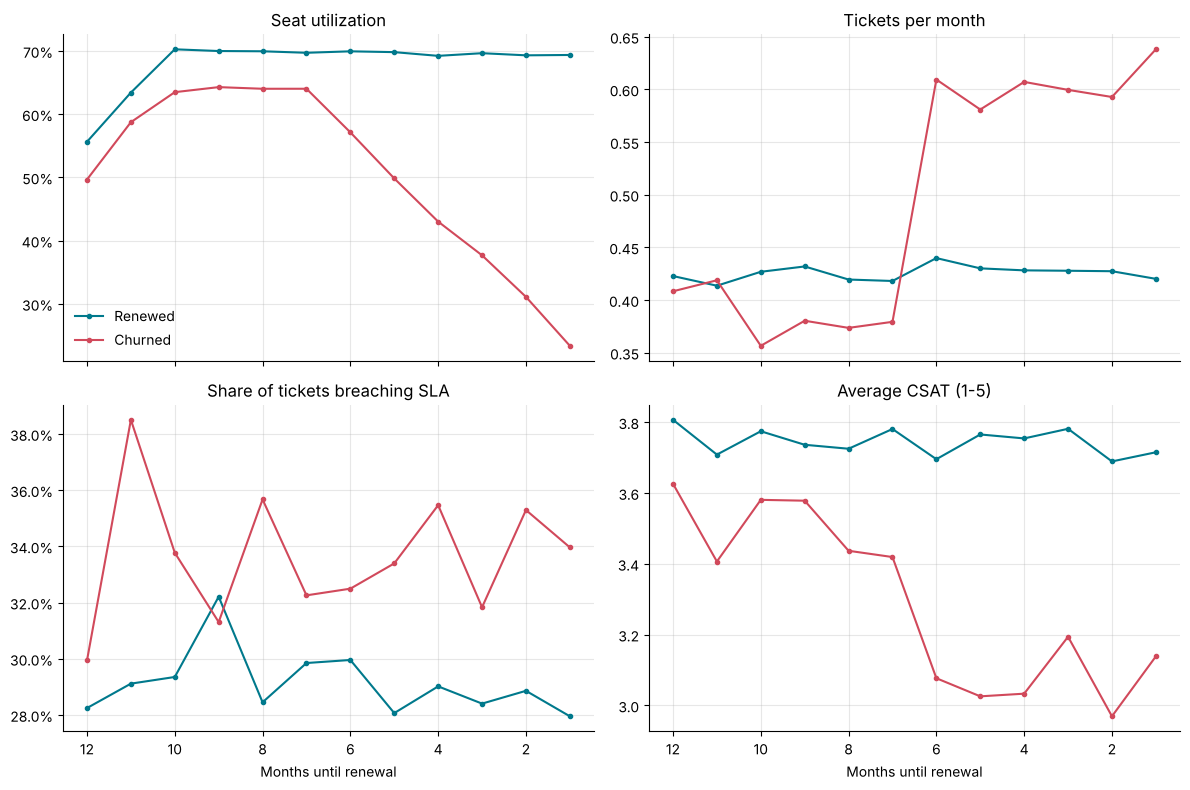

In [7]:
runway = q("""
    SELECT m.months_to_renewal,
           c.renewal_outcome = 'churned'                  AS churned,
           avg(m.seat_utilization)                        AS utilization,
           avg(m.tickets)                                 AS tickets,
           sum(m.sla_breaches) / nullif(sum(m.tickets), 0) AS sla_breach_rate,
           avg(m.avg_csat)                                AS csat
    FROM mart_account_month m
    JOIN fact_contract c USING (contract_id)
    WHERE c.renewal_outcome <> 'open'
    GROUP BY 1, 2
    ORDER BY 1 DESC
""")

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
panels = [("utilization", "Seat utilization", True), ("tickets", "Tickets per month", False),
          ("sla_breach_rate", "Share of tickets breaching SLA", True), ("csat", "Average CSAT (1-5)", False)]
for ax, (col, title, pct) in zip(axes.flat, panels):
    for churned, label, color in [(False, "Renewed", "#00798c"), (True, "Churned", "#d1495b")]:
        d = runway[runway["churned"] == churned]
        ax.plot(d["months_to_renewal"], d[col], marker="o", markersize=3, label=label, color=color)
    ax.set_title(title)
    if pct:
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
# The panels share one x-axis, so flip it once: read left to right toward the renewal date.
axes[0, 0].invert_xaxis()
for ax in axes[1]:
    ax.set_xlabel("Months until renewal")
axes[0, 0].legend(frameon=False)
plt.tight_layout()
plt.show()

In [8]:
# The same comparison as one table: the last 6 months before renewal.
q("""
    SELECT c.renewal_outcome = 'churned'                     AS churned,
           count(DISTINCT m.contract_id)                     AS contracts,
           round(avg(m.seat_utilization), 3)                 AS utilization,
           round(sum(m.tickets) / count(DISTINCT m.contract_id), 2) AS tickets_per_contract,
           round(sum(m.sla_breaches) / sum(m.tickets), 3)    AS sla_breach_rate,
           round(avg(m.avg_csat), 2)                         AS avg_csat
    FROM mart_account_month m
    JOIN fact_contract c USING (contract_id)
    WHERE c.renewal_outcome <> 'open' AND m.months_to_renewal <= 6
    GROUP BY 1
""")

,churned,contracts,utilization,tickets_per_contract,sla_breach_rate,avg_csat
0,False,3525,0.695,2.47,0.287,3.73
1,True,992,0.401,3.49,0.338,3.08


**Answer: yes, and usage is the loudest signal.**

- **Usage collapses.** In the last 6 months, churning customers used about **40%** of their seats,
  against about **70%** for customers who renewed. The two lines split clearly around 6 months out.
- **Support gets worse.** Churning customers file about **40% more tickets** (3.5 vs 2.5 per contract),
  more of those tickets breach SLA (34% vs 29%), and CSAT falls to about **3.1 vs 3.7**.
- **Not every churn is visible.** A few customers churn with healthy-looking usage (for example after
  an acquisition or a budget cut). No model will catch those, and it shouldn't claim to.

**So what:** a CSM looking at usage trends and ticket history 6 months before renewal would catch
most churn in time to act. That is exactly the health score Phase 4 builds.

## 5. Conclusions and recommendations

| Finding | Evidence | Recommendation | Owner |
|---|---|---|---|
| Existing customers are shrinking | NRR 93%, GRR 84% | Make retention a company-level KPI next to new ARR | Exec / RevOps |
| Enterprise churn is the biggest dollar risk | $7.4M lost from 101 logos | Risk review of every Enterprise renewal 6 months out | CS leadership |
| SMB churn is a volume problem | 621 logos lost, GRR ~72% | Tech-touch onboarding and in-app nudges | Product / Marketing |
| Slow starts predict churn | <40% early utilization → 34% churn vs 15% | 90-day onboarding health check | CS / Onboarding |
| Usage and support decline before churn | Utilization 40% vs 70% in last 6 months | Health score combining usage, support, contract signals | Data / CS Ops |

**Inputs to Phase 4 (health score and churn model):** seat utilization and its trend, early-tenure
utilization, ticket volume, urgent tickets, SLA breach rate, CSAT, segment, ARR, and months to renewal.